# ML Model Training to Predict Severity

## Import Libraries

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

## Load Data

In [42]:
df = pd.read_csv("../data/processed/ml_ready_complaints.csv")

In [43]:
target = "severity"
X = df.drop(columns=[target])
Y = df[target]

## View X and Y

In [44]:
print("X shape:", X.shape)
print("Y shape:", Y.shape)

print("\nFeatures:")
print(X.columns)

print("\nSeverity distribution:")
print(Y.value_counts())

X shape: (8953, 7)
Y shape: (8953,)

Features:
Index(['category', 'sub_category', 'people_affected', 'vulnerable_population',
       'public_safety_risk', 'recurrence_indicator',
       'vulnerable_population_ratio'],
      dtype='str')

Severity distribution:
severity
Medium      3530
Low         2710
High        2000
Critical     713
Name: count, dtype: int64


## Split Dataset

In [45]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (7162, 7)
Testing data: (1791, 7)


## Handle Categorical and Numerical Features

In [46]:
categorical_features = X.select_dtypes(
    include=["str"]
).columns

In [47]:
numerical_features = X.select_dtypes(
    include=["number"]
).columns

In [48]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        ),
        (
            "numerical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numerical_features
        )
    ]
)

In [49]:
print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: Index(['category', 'sub_category', 'public_safety_risk',
       'recurrence_indicator'],
      dtype='str')
Numerical features: Index(['people_affected', 'vulnerable_population',
       'vulnerable_population_ratio'],
      dtype='str')


## Define Models

In [50]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

## Train and Compare Models

In [51]:
results = []
trained_models = {}

for name, classifier in models.items():

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model.fit(X_train, Y_train)

    Y_pred = model.predict(X_test)

    accuracy = accuracy_score(Y_test, Y_pred)

    macro_f1 = f1_score(
        Y_test,
        Y_pred,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

    trained_models[name] = model

    print(f"{name} trained successfully!")

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="Macro F1",
        ascending=False
    ).reset_index(drop=True)
)

Logistic Regression trained successfully!
Random Forest trained successfully!
Extra Trees trained successfully!


,Model,Accuracy,Macro F1
0,Random Forest,0.627582,0.628222
1,Extra Trees,0.609157,0.610908
2,Logistic Regression,0.547180,0.534038


## Visualize Model Performance

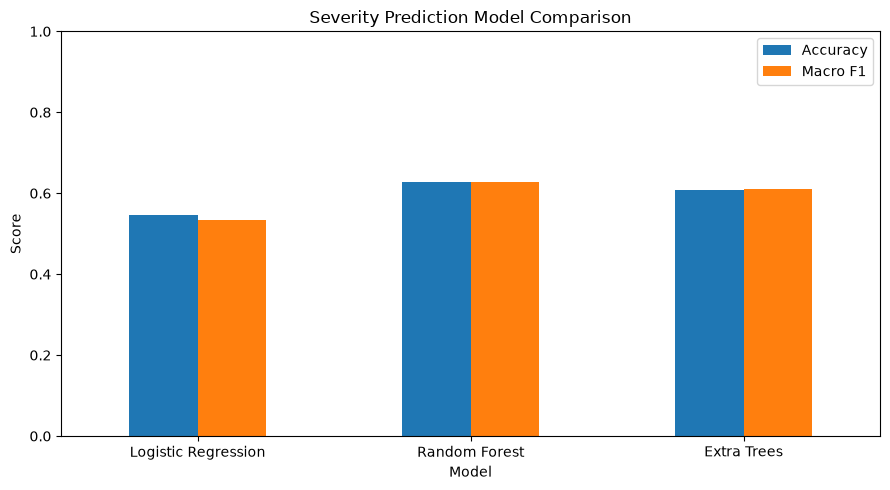

In [52]:
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Severity Prediction Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Select Best Model

In [53]:
best_model_name = results_df.loc[
    results_df["Macro F1"].idxmax(),
    "Model"
]

best_model = trained_models[best_model_name]

print("Best model:", best_model_name)

Best model: Random Forest


## Classification Report

In [54]:
Y_pred = best_model.predict(X_test)

print(classification_report(
    Y_test,
    Y_pred,
    labels=["Low", "Medium", "High", "Critical"],
    zero_division=0
))

              precision    recall  f1-score   support

         Low       0.67      0.72      0.69       542
      Medium       0.64      0.57      0.60       706
        High       0.56      0.58      0.57       400
    Critical       0.62      0.68      0.65       143

    accuracy                           0.63      1791
   macro avg       0.62      0.64      0.63      1791
weighted avg       0.63      0.63      0.63      1791



## Confusion Matrix

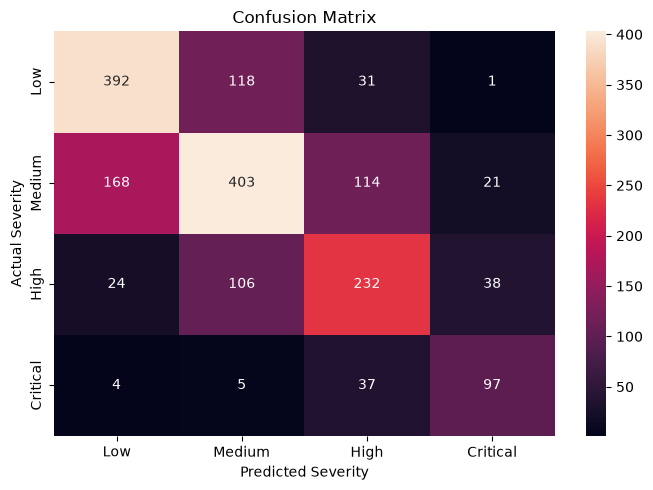

In [58]:
severity_labels = ["Low", "Medium", "High", "Critical"]

cm = confusion_matrix(
    Y_test,
    Y_pred,
    labels=severity_labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=severity_labels,
    yticklabels=severity_labels
)

plt.xlabel("Predicted Severity")
plt.ylabel("Actual Severity")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

## Save Model

In [59]:
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    best_model,
    "../models/severity_prediction_model.joblib"
)

print("Best model saved successfully!")

Best model saved successfully!


## Test Predictions

In [60]:
sample_data = X_test.head(5)

predictions = best_model.predict(sample_data)

sample_results = sample_data.copy()
sample_results["predicted_severity"] = predictions

display(sample_results)

,category,sub_category,people_affected,vulnerable_population,public_safety_risk,recurrence_indicator,vulnerable_population_ratio,predicted_severity
7208,Road Maintenance,Road Surface Damage,160.0,22.0,Medium,Yes,0.137500,High
544,Electrical,Multiple Street Lights Not Working,170.0,40.0,Low,No,0.235294,Medium
8271,Health,Increase in Mosquito Density,5000.0,19.0,High,Yes,0.003800,Critical
355,Water Supply,No Water Supply,280.0,34.0,Medium,No,0.121429,Medium
7851,Health,Stray Dog Menace,50.0,5.0,Medium,Yes,0.100000,Medium
